# 04 Spatial

## Question

Earlier notebooks show NO₂ varies by location. That is a statement about 15
measured points across 892 km². This notebook asks how far a measurement
travels, and what the city's own model adds between the stations.

## Method

- **Part A.** Leave-one-out inverse distance weighting. Hide each station,
  estimate its annual mean from the others weighted by 1/d², compare to the
  measured value. Both pollutants, sensitivity across weighting powers
- **Part B.** Berlin's FAirQ model, 2025 annual means on a 50 × 50 m grid.
  Value at each station against the measurement and against Part A. Then a
  systematic sample across the city for compliance by area

In [1]:
import json
import time
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# One colour system across notebooks.
# Hue = pollutant. Blue/orange is CVD safe.
COLOUR = {"no2": "#4c72b0", "pm2": "#dd8452"}
PALE   = {"no2": "#b8c6de", "pm2": "#f0cab5"}
CMAP   = {"no2": "mako_r", "pm2": "flare"}

CURRENT = {"no2": 40, "pm2": 25}    # annual mean, in force 2025
LIMIT   = {"no2": 20, "pm2": 10}    # annual mean, EU 2030
WHO     = {"no2": 10, "pm2": 5}

# $_2$ renders the subscript. The plain ₂ character draws as a box in figures.
LABEL = {
    "no2": "NO$_2$ · mainly traffic exhaust · airways",
    "pm2": "PM2.5 · fine particles · heart and blood vessels",
}

NAME = {
    "mc010": "Amrumer Str., Wedding",
    "mc027": "Schichauweg, Marienfelde",
    "mc032": "Grunewald, Charlottenburg-Wilmersdorf",
    "mc042": "Nansenstr., Neukölln",
    "mc077": "Buch, Pankow",
    "mc085": "Friedrichshagen, Treptow-Köpenick",
    "mc117": "Schildhornstr., Steglitz",
    "mc124": "Mariendorfer Damm, Mariendorf",
    "mc144": "Silbersteinstr., Neukölln",
    "mc145": "Frohnau, Reinickendorf",
    "mc171": "Brückenstr., Mitte",
    "mc174": "Frankfurter Allee, Friedrichshain",
    "mc190": "Leipziger Str., Mitte",
    "mc221": "Karl-Marx-Str., Neukölln",
    "mc282": "Karlshorst, Lichtenberg",
}

TYPE = {
    "mc010": "background", "mc042": "background",
    "mc171": "background", "mc282": "background",
    "mc027": "suburb", "mc032": "suburb", "mc077": "suburb",
    "mc085": "suburb", "mc145": "suburb",
    "mc117": "traffic", "mc124": "traffic", "mc144": "traffic",
    "mc174": "traffic", "mc190": "traffic", "mc221": "traffic",
}

# Cleaned table from 01. Drops and fireworks flag already applied.
# CSV stores the offset as text, so parse to UTC then convert, as in 01.
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "processed" / "hourly.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Berlin")
df["fireworks"] = df["fireworks"].astype(bool)      # survives CSV as text otherwise
RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

print(df.shape)

(236180, 7)


In [2]:
# Station coordinates are not in the hourly data. One request to /api/stations,
# cached like the measurement files so the notebook reruns without the network.
import json
from urllib.request import urlopen

RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)
path = RAW / "stations.json"

if path.exists():
    stations = json.loads(path.read_text())
else:
    with urlopen("https://luftdaten.berlin.de/api/stations?active=true") as r:
        text = r.read().decode()
    path.write_text(text)
    stations = json.loads(text)

print(type(stations), len(stations))
print(json.dumps(stations[0] if isinstance(stations, list) else stations, indent=2)[:800])

<class 'list'> 15
{
  "name": "010 Wedding",
  "code": "mc010",
  "codeEu": "DEBE010",
  "address": "13353 Berlin, Amrumer Str./Limburger Str.",
  "lat": "52.54291000",
  "lng": "13.34926000",
  "active": true,
  "stationgroups": [
    "background"
  ],
  "measuringStart": "1984-11-01T00:00:00+01:00",
  "measuringEnd": null,
  "measuringHeight": null,
  "url": "https://gdi.berlin.de/data/ua_luftguetemessnetz/pictures/MC010-Doku.pdf",
  "information": "Die Station befindet sich an der Beuth Hochschule f\u00fcr Technik. Hat MP910 ersetzt.",
  "components": [
    "pm10_1h",
    "pm10_24h",
    "pm10_24hg",
    "pm10_1m",
    "pm10_1y",
    "no_1h",
    "no_24h",
    "no_1m",
    "no_1y",
    "no2_1h",
    "no2_24h",
    "no2_1m",
    "no2_1y",
    "nox_1h",
    "nox_24h",
    "nox_1m",
    "nox_1y",
    "chb_1


In [3]:
# Build a station table from the API: coordinates, group, and whether a
# measuring height is published. Strings to floats; lat/lng are WGS84.
st = pd.DataFrame(
    [
        {
            "station": s["code"],
            "name": s["name"],
            "lat": float(s["lat"]),
            "lng": float(s["lng"]),
            "group": s["stationgroups"][0] if s["stationgroups"] else None,
            "height": s["measuringHeight"],
        }
        for s in stations
    ]
).set_index("station")

print(st["group"].value_counts())
print("heights published:", st["height"].notna().sum(), "of", len(st))
print(st[["lat", "lng"]].agg(["min", "max"]))
st

group
traffic       6
suburb        5
background    4
Name: count, dtype: int64
heights published: 3 of 15
          lat       lng
min  52.39840  13.22514
max  52.65327  13.64705


,name,lat,lng,group,height
station,,,,,
mc010,010 Wedding,52.542910,13.349260,background,NaN
mc027,027 Marienfelde,52.398400,13.368075,suburb,NaN
mc032,032 Grunewald,52.473190,13.225140,suburb,3.0
mc042,042 Neukölln,52.489451,13.430844,background,NaN
mc077,077 Buch,52.644100,13.483300,suburb,NaN
mc085,085 Friedrichshagen,52.447697,13.647050,suburb,NaN
mc117,117 Schildhornstraße,52.463620,13.318320,traffic,NaN
mc124,124 Mariendorfer Damm,52.438115,13.387720,traffic,NaN
mc145,145 Frohnau,52.653270,13.296080,suburb,NaN


In [4]:
# Pairwise great-circle distances in km. Haversine on WGS84 coordinates;
# over 40 km a spherical approximation is accurate to a few metres.
import numpy as np

lat = np.radians(st["lat"].to_numpy())
lng = np.radians(st["lng"].to_numpy())

dlat = lat[:, None] - lat[None, :]
dlng = lng[:, None] - lng[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlng / 2) ** 2
dist = pd.DataFrame(
    6371.0 * 2 * np.arcsin(np.sqrt(a)), index=st.index, columns=st.index
)

# Nearest other station per station: how dense is the network, really?
nearest = dist.replace(0, np.nan).min()
print(nearest.round(1).sort_values())
print("median nearest neighbour:", round(nearest.median(), 1), "km")

station
mc042     0.6
mc221     0.6
mc144     2.0
mc171     2.5
mc190     2.5
mc174     3.5
mc010     4.3
mc027     4.6
mc124     4.6
mc282     5.1
mc117     5.5
mc032     6.4
mc085     9.0
mc077    12.7
mc145    12.7
dtype: float64
median nearest neighbour: 4.6 km


Three stations publish a measuring height: 40 m, 35 m, 3 m. Twelve report null.
`stationgroups` matches the hard-coded TYPE dict in 02 and 03 (6 traffic,
5 suburb, 4 background), so the grouping is the operator's, not ours.

In [5]:
# Distance between every pair of stations in km, from WGS84 coordinates.
# Haversine: accurate to metres over a city.
lat = np.radians(st["lat"].to_numpy())
lng = np.radians(st["lng"].to_numpy())
a = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat[None, :])
     * np.sin((lng[:, None] - lng[None, :]) / 2) ** 2)
dist = pd.DataFrame(6371 * 2 * np.arcsin(np.sqrt(a)), index=st.index, columns=st.index)

# Nearest other station: how dense the network really is.
nearest = dist.replace(0, np.nan).min()
print(nearest.round(1).sort_values())
print("median nearest neighbour:", round(nearest.median(), 1), "km")

station
mc042     0.6
mc221     0.6
mc144     2.0
mc171     2.5
mc190     2.5
mc174     3.5
mc010     4.3
mc027     4.6
mc124     4.6
mc282     5.1
mc117     5.5
mc032     6.4
mc085     9.0
mc077    12.7
mc145    12.7
dtype: float64
median nearest neighbour: 4.6 km


In [6]:
# Annual mean per station. These are the values the holdout tries to recover.
ann = df.groupby(["core", "station"])["value"].mean().rename("measured").reset_index()
ann["group"] = ann["station"].map(st["group"])
ann["name"] = ann["station"].map(NAME)

In [7]:
# Hide one station, estimate it from the others weighted by 1/d^power,
# compare to what it measured. Repeat for every station.
def loo_idw(core, power=2):
    g = ann[ann["core"] == core].set_index("station")
    rows = []
    for s in g.index:
        others = g.index.drop(s)
        w = 1 / dist.loc[s, others] ** power
        pred = (w * g.loc[others, "measured"]).sum() / w.sum()
        rows.append((s, g.loc[s, "measured"], pred))
    r = pd.DataFrame(rows, columns=["station", "measured", "predicted"]).set_index("station")
    r["error"] = r["predicted"] - r["measured"]
    r["core"] = core
    return r

res = pd.concat([loo_idw("no2"), loo_idw("pm2")])
res["group"] = res.index.map(st["group"])
res["name"] = res.index.map(NAME)

In [8]:
# Mean absolute error, and the same as a share of the pollutant's mean,
# so NO₂ and PM2.5 compare despite their different levels.
summary = res.groupby("core").agg(
    mae=("error", lambda e: e.abs().mean()),
    max_ae=("error", lambda e: e.abs().max()),
    mean=("measured", "mean"),
)
summary["mae_pct"] = summary["mae"] / summary["mean"] * 100
print(summary.round(1))

# Signed error by station type. Negative means interpolation underestimates.
print(res.groupby(["core", "group"])["error"].mean().round(1))

      mae  max_ae  mean  mae_pct
core                            
no2   7.1    12.6  16.1     44.0
pm2   1.6     3.7  11.5     13.5
core  group     
no2   background    5.0
      suburb        9.9
      traffic      -5.3
pm2   background    1.0
      suburb        3.1
      traffic      -0.7
Name: error, dtype: float64


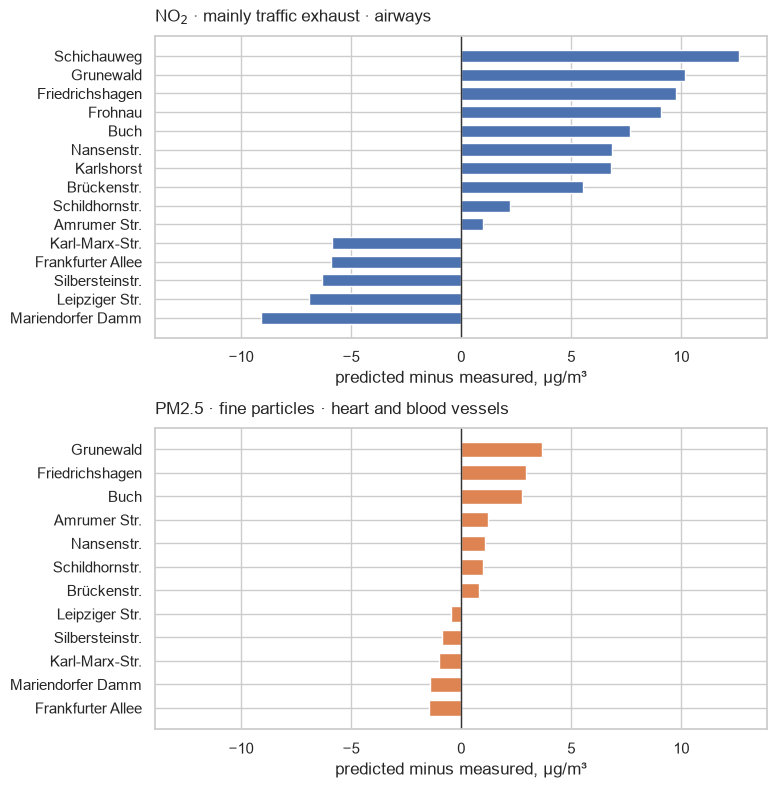

In [9]:
# Prediction error per station. Negative: interpolation reads it too low.
# Same x scale in both panels so the pollutants compare directly.
lim = res["error"].abs().max() * 1.1
fig, axes = plt.subplots(2, 1, figsize=(9, 9))

for ax, core in zip(axes, ["no2", "pm2"]):
    g = res[res["core"] == core].sort_values("error")
    ax.barh(g["name"].str.split(", ").str[0], g["error"], color=COLOUR[core], height=0.65)
    ax.axvline(0, color="#333333", lw=1)
    ax.set_xlim(-lim, lim)
    ax.set_title(LABEL[core], pad=10, loc="left")
    ax.set_xlabel("predicted minus measured, µg/m³")

plt.subplots_adjust(left=0.28, right=0.96, hspace=0.3)
plt.savefig(ROOT / "figures" / "04_holdout_error.png", dpi=150, pad_inches=0.3)

In [10]:
# Does the result depend on the method? Power 1 spreads influence widely,
# power 6 trusts the nearest station almost entirely.
sens = pd.DataFrame({
    f"power {p}": pd.concat([loo_idw("no2", p), loo_idw("pm2", p)])
                    .groupby("core")["error"].apply(lambda e: e.abs().mean())
    for p in [1, 2, 3, 6]
}).round(1)
sens

,power 1,power 2,power 3,power 6
core,,,,
no2,6.6,7.1,7.4,7.8
pm2,1.5,1.6,1.6,1.6


## Findings

- Leave-one-out interpolation smooths toward the middle: clean stations are
  overestimated, traffic stations underestimated, for both pollutants
- NO₂: misses of roughly 5 to 13 µg/m³ at most stations. Mean absolute error
  [value] µg/m³, [value] % of the mean
- The NO₂ error exceeds the 10 µg/m³ gap between the WHO level and the 2030
  limit, so an interpolated value cannot place a location relative to the limit
- Error follows station type rather than distance. Main-road stations miss low
  by 6 to 9, edge stations miss high by 8 to 13
- PM2.5: same pattern, mostly under 2 µg/m³, largest at Grunewald.
  Mean absolute error [value] µg/m³, [value] % of the mean
- Schildhornstr. is overestimated despite being a traffic station, consistent
  with its small traffic increment in 02

## Decisions

- Inverse distance weighting, power 2, on annual means. Sensitivity checked
  with powers 1, 3 and 6
- Edge stations are extrapolated rather than interpolated. Kept, and named

## Open

- Whether the city model, which uses road and urban-structure data, recovers
  the traffic stations that interpolation misses. Part B

In [11]:
# The 2025 model is published as WMS (confirmed). A WFS under the same name
# would give the actual cell values; test both before relying on either.
from urllib.error import HTTPError, URLError

BASE = "https://gdi.berlin.de/services/{kind}/ua_luftschadstoffbelastung"

for kind in ["wfs", "wms"]:
    url = BASE.format(kind=kind) + f"?service={kind.upper()}&request=GetCapabilities"
    try:
        with urlopen(url, timeout=30) as r:
            caps = r.read()
        (RAW / f"model_caps_{kind}.xml").write_bytes(caps)
        print(kind, "ok", len(caps), "bytes")
    except (HTTPError, URLError) as e:
        print(kind, "failed:", e)

wfs ok 94454 bytes
wms ok 18468 bytes


In [12]:
# Layer names, and for WMS whether a layer can be queried at a point.
import xml.etree.ElementTree as ET

for kind, tag in [("wfs", "FeatureType"), ("wms", "Layer")]:
    p = RAW / f"model_caps_{kind}.xml"
    if not p.exists():
        continue
    root = ET.fromstring(p.read_bytes())
    for el in root.iter():
        if el.tag.endswith(tag):
            name = next((c.text for c in el if c.tag.endswith("Name")), None)
            title = next((c.text for c in el if c.tag.endswith("Title")), "")
            if name:
                print(kind, "|", name, "|", title, "| queryable:", el.get("queryable"))

wms | a_pollutant_grid_avg_no2_2024 | NO2 – Stickstoffdioxid in µg/m³ 2024 | queryable: 1
wms | b_pollutant_grid_avg_pm10_2024 | PM10 – Partikel < 10 µm in µg/m³ 2024 | queryable: 1
wms | c_pollutant_grid_avg_pm2_5_2024 | PM2,5 – Partikel < 2,5 µm in µg/m³ 2024 | queryable: 1


In [13]:
# Read the WFS capabilities as text: layer names, whether 2025 appears,
# and which output formats are offered.
import re

txt = (RAW / "model_caps_wfs.xml").read_text(encoding="utf-8")
names = re.findall(r"<(?:\w+:)?Name>([^<]+)</(?:\w+:)?Name>", txt)
print([n for n in names if "pollutant" in n or "luft" in n.lower()])
print("2025 mentioned:", "2025" in txt)
print("formats:", sorted({f for f in re.findall(r">([^<>]*(?:json|gpkg|geopackage)[^<>]*)<", txt, re.I)}))

[]
2025 mentioned: False
formats: ['application/json', 'geopackage', 'gpkg', 'json']


In [14]:
# The 2025 edition may sit under its own service name. Test, do not assume.
for name in ["ua_luftschadstoffbelastung_2025", "ua_luftschadstoffbelastung2025"]:
    url = f"https://gdi.berlin.de/services/wfs/{name}?service=WFS&request=GetCapabilities"
    try:
        with urlopen(url, timeout=30) as r:
            body = r.read()
        print(name, "ok", len(body), "bytes")
        (RAW / f"model_caps_{name}.xml").write_bytes(body)
    except (HTTPError, URLError) as e:
        print(name, "failed:", e)

ua_luftschadstoffbelastung_2025 ok 94539 bytes
ua_luftschadstoffbelastung2025 failed: HTTP Error 404: Not Found


In [15]:
# The 2025 model has its own service. Layer names and output formats.
WFS = "https://gdi.berlin.de/services/wfs/ua_luftschadstoffbelastung_2025"

txt = (RAW / "model_caps_ua_luftschadstoffbelastung_2025.xml").read_text(encoding="utf-8")
layers = [n for n in re.findall(r"<(?:\w+:)?Name>([^<]+)</(?:\w+:)?Name>", txt)
          if "pollutant" in n]
print(layers)
print("formats:", sorted({f for f in re.findall(
    r">([^<>]*(?:json|gpkg|geopackage)[^<>]*)<", txt, re.I)}))

[]
formats: ['application/json', 'geopackage', 'gpkg', 'json']


In [16]:
# Every name in the 2025 capabilities, unfiltered, to see how layers are called.
txt = (RAW / "model_caps_ua_luftschadstoffbelastung_2025.xml").read_text(encoding="utf-8")
names = re.findall(r"<(?:\w+:)?Name>([^<]+)</(?:\w+:)?Name>", txt)
for n in names:
    print(n)

In [17]:
# The pattern found nothing. Look at the file itself.
print(len(txt))
print(txt[:800])
print("FeatureType count:", txt.count("FeatureType"))

i = txt.find("FeatureType")
print(txt[i:i + 1500])

94532
<?xml version="1.0" encoding="UTF-8"?><wfs:WFS_Capabilities version="2.0.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xmlns="http://www.opengis.net/wfs/2.0" xmlns:wfs="http://www.opengis.net/wfs/2.0" xmlns:ows="http://www.opengis.net/ows/1.1" xmlns:gml="http://www.opengis.net/gml/3.2" xmlns:fes="http://www.opengis.net/fes/2.0" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns:xs="http://www.w3.org/2001/XMLSchema" xsi:schemaLocation="http://www.opengis.net/wfs/2.0 http://schemas.opengis.net/wfs/2.0/wfs.xsd http://inspire.ec.europa.eu/schemas/inspire_dls/1.0 https://inspire.ec.europa.eu/schemas/inspire_dls/1.0/inspire_dls.xsd" xmlns:xml="http://www.w3.org/XML/1998/namespace" xmlns:inspire_dls="http://inspire.ec.europa.eu/schemas/inspire_dls/1.0" xmlns:inspire_common="http://inspir
FeatureType count: 2
FeatureTypeList</ows:Value><ows:Value>Filter_Capabilities</ows:Value></ows:AllowedValues></ows:Parameter></ows:Operation><ows:Operation name="DescribeFeatureType"><ows:DCP>

In [18]:
# The WFS lists no layers, so the grid cannot be downloaded as features.
# The WMS serves it as queryable layers: ask for values at points instead.
WMS = "https://gdi.berlin.de/services/wms/ua_luftschadstoffbelastung_2025"

with urlopen(f"{WMS}?service=WMS&request=GetCapabilities", timeout=30) as r:
    wcaps = r.read().decode("utf-8")
(RAW / "model_caps_wms_2025.xml").write_text(wcaps, encoding="utf-8")

wms_layers = re.findall(r'<Layer[^>]*queryable="1"[^>]*>\s*<Name>([^<]+)</Name>', wcaps)
print(wms_layers)

block = re.search(r"<GetFeatureInfo>(.*?)</GetFeatureInfo>", wcaps, re.S)
print(re.findall(r"<Format>([^<]+)</Format>", block.group(1)) if block else "no GetFeatureInfo")

['a_pollutant_grid_avg_no2_2025', 'b_pollutant_grid_avg_pm10_2025', 'c_pollutant_grid_avg_pm2_5_2025']
['text/plain', 'application/vnd.ogc.gml', 'text/xml', 'application/vnd.ogc.gml/3.1.1', 'text/xml; subtype=gml/3.1.1', 'text/html', 'application/json']


In [19]:
# The WFS lists no layers, so the grid cannot be downloaded as features.
# The WMS serves it as queryable layers: ask for the value at a point instead.
WMS = "https://gdi.berlin.de/services/wms/ua_luftschadstoffbelastung_2025"

with urlopen(f"{WMS}?service=WMS&request=GetCapabilities", timeout=30) as r:
    wcaps = r.read().decode("utf-8")
(RAW / "model_caps_wms_2025.xml").write_text(wcaps, encoding="utf-8")

wms_layers = re.findall(r'<Layer[^>]*queryable="1"[^>]*>\s*<Name>([^<]+)</Name>', wcaps)
block = re.search(r"<GetFeatureInfo>(.*?)</GetFeatureInfo>", wcaps, re.S)
print("layers:", wms_layers)
print("formats:", re.findall(r"<Format>([^<]+)</Format>", block.group(1)) if block else None)


# Value of the cell under a point: a small box around the station, query its centre
# pixel. WMS 1.3.0 with EPSG:4326 takes latitude first.
def wms_value(layer, lat, lng, half=0.0005):
    q = ("service=WMS&version=1.3.0&request=GetFeatureInfo"
         f"&layers={layer}&query_layers={layer}&styles="
         f"&crs=EPSG:4326&bbox={lat-half},{lng-half},{lat+half},{lng+half}"
         "&width=101&height=101&i=50&j=50&info_format=application/json")
    with urlopen(f"{WMS}?{q}", timeout=60) as r:
        return json.loads(r.read())


no2 = [l for l in wms_layers if "no2" in l.lower()]
if no2:
    out = wms_value(no2[0], st.loc["mc124", "lat"], st.loc["mc124", "lng"])
    print(no2[0])
    print(json.dumps(out, indent=2)[:1500])
else:
    print("No NO2 layer found. Check the layer list above.")

layers: ['a_pollutant_grid_avg_no2_2025', 'b_pollutant_grid_avg_pm10_2025', 'c_pollutant_grid_avg_pm2_5_2025']
formats: ['text/plain', 'application/vnd.ogc.gml', 'text/xml', 'application/vnd.ogc.gml/3.1.1', 'text/xml; subtype=gml/3.1.1', 'text/html', 'application/json']
a_pollutant_grid_avg_no2_2025
{
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "id": "",
      "properties": {
        "NO2-Jahresmittelwert": "28.0"
      }
    }
  ],
  "totalFeatures": "unknown",
  "numberReturned": 1,
  "timeStamp": "2026-10-13T10:31:55.674Z",
  "crs": {
    "type": "name",
    "properties": {
      "name": "EPSG:4326"
    }
  }
}
